In [1]:
import sys
import pathlib
import pandas as pd

_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))

from db.dataraflow_db import run_query

In [2]:
test=run_query(
    "SELECT CURRENT_USER AS username"
)
test

,username
0,intern_readonly


In [3]:
london=run_query(
    "SELECT * FROM week07.london_2014"
)
london.head

<bound method NDFrame.head of             GMT  Max TemperatureC  Mean TemperatureC  Min TemperatureC  \
0      2014-1-1                11                  8                 6   
1      2014-1-2                11                  9                 6   
2      2014-1-3                11                  8                 6   
3      2014-1-4                 9                  6                 3   
4      2014-1-5                12                  7                 1   
..          ...               ...                ...               ...   
360  2014-12-27                 4                  3                 2   
361  2014-12-28                 6                  2                -2   
362  2014-12-29                 6                  1                -4   
363  2014-12-30                 6                  1                -4   
364  2014-12-31                 8                  2                -4   

     Dew PointC  MeanDew PointC  Min DewpointC  Max Humidity   Mean Humidity  \
0

In [4]:
london.columns.tolist()

['GMT',
 'Max TemperatureC',
 'Mean TemperatureC',
 'Min TemperatureC',
 'Dew PointC',
 'MeanDew PointC',
 'Min DewpointC',
 'Max Humidity',
 ' Mean Humidity',
 ' Min Humidity',
 ' Max Sea Level PressurehPa',
 ' Mean Sea Level PressurehPa',
 ' Min Sea Level PressurehPa',
 ' Max VisibilityKm',
 ' Mean VisibilityKm',
 ' Min VisibilitykM',
 ' Max Wind SpeedKm/h',
 ' Mean Wind SpeedKm/h',
 ' Max Gust SpeedKm/h',
 'Precipitationmm',
 ' CloudCover',
 ' Events',
 'WindDirDegrees<br />']

In [5]:
gdpReset = run_query(
    "SELECT * FROM week08.wb_gdp_2013"
)

lifeReset = run_query(
    "SELECT * FROM week08.wb_le_2013"
)

popReset = run_query(
    "SELECT * FROM week08.wb_pop_2013"
)

In [6]:
print(gdpReset.columns.tolist())
print(lifeReset.columns.tolist())
print(popReset.columns.tolist())

['country', 'year', 'NY.GDP.MKTP.CD']
['country', 'year', 'SP.DYN.LE00.IN']
['country', 'year', 'SP.POP.TOTL']


PART A_CLEANING AND VISUALAIZING THE DATA

In [7]:
london.columns=london.columns.str.strip()
print(london.columns)


Index(['GMT', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC',
       'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity',
       'Mean Humidity', 'Min Humidity', 'Max Sea Level PressurehPa',
       'Mean Sea Level PressurehPa', 'Min Sea Level PressurehPa',
       'Max VisibilityKm', 'Mean VisibilityKm', 'Min VisibilitykM',
       'Max Wind SpeedKm/h', 'Mean Wind SpeedKm/h', 'Max Gust SpeedKm/h',
       'Precipitationmm', 'CloudCover', 'Events', 'WindDirDegrees<br />'],
      dtype='str')


In [8]:
london["WindDirDegrees<br />"].head()

0    186<br />
1    214<br />
2    219<br />
3    211<br />
4    199<br />
Name: WindDirDegrees<br />, dtype: str

In [9]:
london=london.rename(columns={"WindDirDegrees<br />": "WindDirDegrees"}
)


In [10]:
london["WindDirDegrees"]= london["WindDirDegrees"].astype(str).str.replace("<br />", "", regex=False)
london["WindDirDegrees"].head()

0    186
1    214
2    219
3    211
4    199
Name: WindDirDegrees, dtype: str

In [11]:
london["WindDirDegrees"]= london["WindDirDegrees"].astype(int)
london["WindDirDegrees"].head()

0    186
1    214
2    219
3    211
4    199
Name: WindDirDegrees, dtype: int64

In [12]:
london[london["WindDirDegrees"] >350]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
100,2014-4-11,16,12,9,5,4,2,71,53,28,...,31,18,10,13,8,NaN,0.00,1.0,NaN,351
110,2014-4-21,19,12,5,11,8,4,100,78,31,...,26,7,0,14,6,NaN,9.91,3.0,Fog-Rain-Thunderstorm,356
249,2014-9-7,21,17,13,14,12,8,94,71,41,...,23,10,2,11,6,NaN,0.00,4.0,NaN,354
250,2014-9-8,22,16,10,13,9,7,94,64,28,...,27,12,5,11,6,NaN,0.00,1.0,NaN,351
335,2014-12-2,8,7,6,7,4,2,100,80,62,...,31,11,1,27,13,NaN,1.02,5.0,Rain,359


In [13]:
london.isna().sum()

GMT                             0
Max TemperatureC                0
Mean TemperatureC               0
Min TemperatureC                0
Dew PointC                      0
MeanDew PointC                  0
Min DewpointC                   0
Max Humidity                    0
Mean Humidity                   0
Min Humidity                    0
Max Sea Level PressurehPa       0
Mean Sea Level PressurehPa      0
Min Sea Level PressurehPa       0
Max VisibilityKm                0
Mean VisibilityKm               0
Min VisibilitykM                0
Max Wind SpeedKm/h              0
Mean Wind SpeedKm/h             0
Max Gust SpeedKm/h            234
Precipitationmm                 0
CloudCover                     10
Events                        114
WindDirDegrees                  0
dtype: int64

In [14]:
london["Max Gust SpeedKm/h"]= london["Max Gust SpeedKm/h"].fillna(0)

In [15]:
london["Events"]= london["Events"].fillna("No Events")

In [16]:
london["CloudCover"]= london["CloudCover"].fillna("No CloudCover")

In [17]:
london[london["WindDirDegrees"] >350]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
100,2014-4-11,16,12,9,5,4,2,71,53,28,...,31,18,10,13,8,0.0,0.00,1.0,No Events,351
110,2014-4-21,19,12,5,11,8,4,100,78,31,...,26,7,0,14,6,0.0,9.91,3.0,Fog-Rain-Thunderstorm,356
249,2014-9-7,21,17,13,14,12,8,94,71,41,...,23,10,2,11,6,0.0,0.00,4.0,No Events,354
250,2014-9-8,22,16,10,13,9,7,94,64,28,...,27,12,5,11,6,0.0,0.00,1.0,No Events,351
335,2014-12-2,8,7,6,7,4,2,100,80,62,...,31,11,1,27,13,0.0,1.02,5.0,Rain,359


In [18]:
london.isna().sum()

GMT                           0
Max TemperatureC              0
Mean TemperatureC             0
Min TemperatureC              0
Dew PointC                    0
MeanDew PointC                0
Min DewpointC                 0
Max Humidity                  0
Mean Humidity                 0
Min Humidity                  0
Max Sea Level PressurehPa     0
Mean Sea Level PressurehPa    0
Min Sea Level PressurehPa     0
Max VisibilityKm              0
Mean VisibilityKm             0
Min VisibilitykM              0
Max Wind SpeedKm/h            0
Mean Wind SpeedKm/h           0
Max Gust SpeedKm/h            0
Precipitationmm               0
CloudCover                    0
Events                        0
WindDirDegrees                0
dtype: int64

In [19]:
london["GMT"]=pd.to_datetime(london["GMT"])
print(london.dtypes)

GMT                           datetime64[us]
Max TemperatureC                       int64
Mean TemperatureC                      int64
Min TemperatureC                       int64
Dew PointC                             int64
MeanDew PointC                         int64
Min DewpointC                          int64
Max Humidity                           int64
Mean Humidity                          int64
Min Humidity                           int64
Max Sea Level PressurehPa              int64
Mean Sea Level PressurehPa             int64
Min Sea Level PressurehPa              int64
Max VisibilityKm                       int64
Mean VisibilityKm                      int64
Min VisibilitykM                       int64
Max Wind SpeedKm/h                     int64
Mean Wind SpeedKm/h                    int64
Max Gust SpeedKm/h                   float64
Precipitationmm                      float64
CloudCover                            object
Events                                   str
WindDirDeg

In [20]:
london["GMT"].head()

0   2014-01-01
1   2014-01-02
2   2014-01-03
3   2014-01-04
4   2014-01-05
Name: GMT, dtype: datetime64[us]

In [21]:
from datetime import datetime
dates=london['GMT']
start=datetime(2014,4,8)
end=datetime(2014,12,12)
london[(dates >= start) & (dates <= end)]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
97,2014-04-08,14,9,5,6,3,-1,87,64,26,...,31,15,10,39,23,0.0,0.00,2.0,Rain,269
98,2014-04-09,17,10,4,7,6,3,93,68,38,...,31,14,6,23,13,0.0,0.00,2.0,No Events,261
99,2014-04-10,16,11,6,6,5,3,93,62,31,...,31,14,9,19,10,0.0,0.00,3.0,No Events,278
100,2014-04-11,16,12,9,5,4,2,71,53,28,...,31,18,10,13,8,0.0,0.00,1.0,No Events,351
101,2014-04-12,14,10,6,7,5,3,87,66,42,...,31,16,10,29,11,0.0,0.00,1.0,No Events,262
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,2014-12-08,7,4,1,2,1,-1,93,76,51,...,31,17,10,23,13,0.0,0.00,2.0,Rain,270
342,2014-12-09,12,6,-1,11,3,-1,100,86,64,...,31,15,3,37,14,52.0,0.25,5.0,Rain,224
343,2014-12-10,9,7,6,11,3,1,90,70,44,...,31,18,3,40,27,0.0,0.00,2.0,Rain,246
344,2014-12-11,10,8,5,6,3,2,82,72,51,...,31,15,10,40,31,0.0,0.25,2.0,Rain,246


In [22]:
london=london.set_index("GMT").sort_index()

<Axes: xlabel='GMT'>

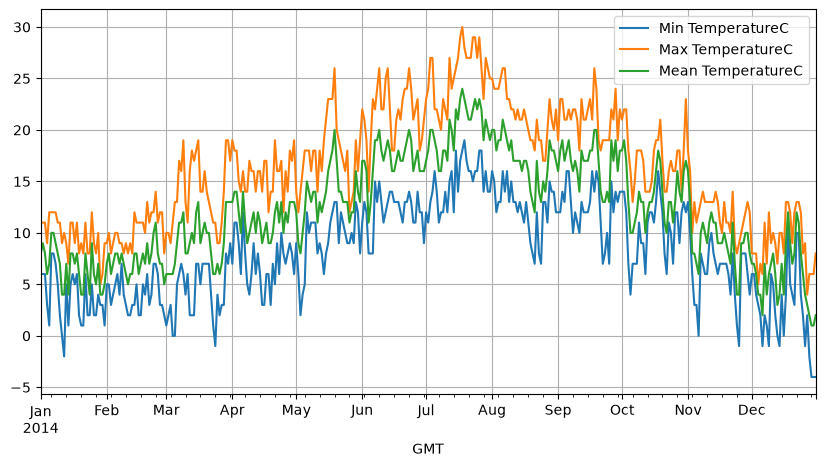

In [23]:
london[[
    "Min TemperatureC",
    "Max TemperatureC",
    "Mean TemperatureC"
    
]].plot(grid=True,figsize=(10,5))

In [24]:
from datetime import datetime
summer_start=datetime(2014,6,1)
summer_end=datetime(2014,8,3)
summer=london.loc[summer_start:summer_end]

<Axes: xlabel='GMT'>

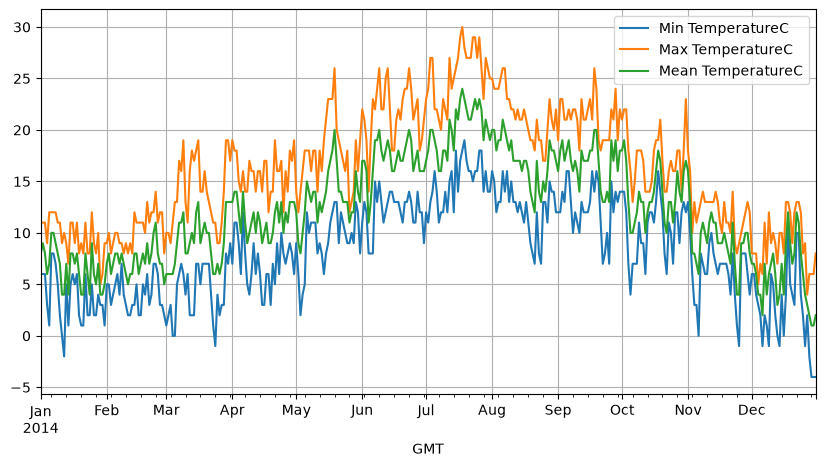

In [25]:
london[[
    "Min TemperatureC",
    "Max TemperatureC",
    "Mean TemperatureC"
    
]].plot(grid=True,figsize=(10,5))

In [26]:


gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")
popReset = run_query("SELECT * FROM week08.wb_pop_2013")

display(gdpReset.head())
display(lifeReset.head())
display(popReset.head())

print("GDP table:", gdpReset.shape)
print("Life expectancy table:", lifeReset.shape)
print("Population table:", popReset.shape)

,country,year,NY.GDP.MKTP.CD
0,Arab World,2013,2.827557e+12
1,Caribbean small states,2013,6.928705e+10
2,Central Europe and the Baltics,2013,1.419384e+12
3,East Asia & Pacific (all income levels),2013,2.084673e+13
4,East Asia & Pacific (developing only),2013,1.172940e+13


,country,year,SP.DYN.LE00.IN
0,Arab World,2013,70.631305
1,Caribbean small states,2013,71.901964
2,Central Europe and the Baltics,2013,76.127583
3,East Asia & Pacific (all income levels),2013,74.604619
4,East Asia & Pacific (developing only),2013,73.657617


,country,year,SP.POP.TOTL
0,Arab World,2013,3.770967e+08
1,Caribbean small states,2013,6.975819e+06
2,Central Europe and the Baltics,2013,1.037137e+08
3,East Asia & Pacific (all income levels),2013,2.248867e+09
4,East Asia & Pacific (developing only),2013,2.006073e+09


GDP table: (248, 3)
Life expectancy table: (248, 3)
Population table: (248, 3)


PROJECT A

In [77]:
import pandas as pd

london_heathrow_2023=pd.read_csv(
    "london_heathrow_2023.csv",
    skiprows=1,
    skipinitialspace=True
)

In [87]:
london_heathrow_2023.rename(columns={london_heathrow_2023.columns[0]: 'Date'},
inplace=True
)

In [88]:
print(london_heathrow_2023.columns.tolist())

['Date', 'Max', 'Avg', 'Min', 'Max.1', 'Avg.1', 'Min.1', 'Max.2', 'Avg.2', 'Min.2', 'Max.3', 'Avg.3', 'Min.3', 'Max.4', 'Avg.4', 'Min.4', 'Unnamed: 16']


In [90]:
london_heathrow_2023.head()

,Date,Max,Avg,Min,Max.1,Avg.1,Min.1,Max.2,Avg.2,Min.2,Max.3,Avg.3,Min.3,Max.4,Avg.4,Min.4,Unnamed: 16
0,1/30/2023,10,7.1,3,7,2.7,1,93,74.4,57,20,14.2,7,1025.0,1021.9,1018.0,0
1,1/29/2023,9,6.3,4,7,4.2,2,93,86.3,81,24,15.4,6,1028.0,1023.1,1019.0,0
2,1/28/2023,6,4.5,2,3,0.4,-2,93,75.3,65,13,6.4,0,1029.9,1028.6,1028.0,0
3,1/27/2023,7,4.5,2,3,1.5,0,93,81.4,61,17,8.9,4,1028.9,1027.5,1027.0,0
4,1/26/2023,8,5.1,3,5,2.7,1,93,84.8,76,17,12.0,6,1028.9,1027.2,1026.0,0


In [91]:
import pandas as pd
df = pd.read_csv("london_heathrow_2023.csv", skipinitialspace=True)
df.columns = df.columns.str.strip()
print(df.tail())
print(f"Total days: {len(df)}")

          Date Temperature (°C) Unnamed: 2 Unnamed: 3 Dew Point (°C)  \
360  12/5/2023                7        6.1          5              5   
361  12/4/2023                8        6.7          6              7   
362  12/3/2023                8        5.6         -1              8   
363  12/2/2023                0       -1.1         -2             -1   
364  12/1/2023                3        0.3         -2              0   

    Unnamed: 5 Unnamed: 6 Humidity (%) Unnamed: 8 Unnamed: 9  \
360        4.4          3           93       88.6         81   
361        5.6          5          100       92.6         87   
362        4.3         -2          100       91.4         81   
363       -1.7         -3          100       95.8         93   
364       -1.2         -3          100       89.7         75   

    Wind Speed (km/h) Unnamed: 11 Unnamed: 12 Pressure (hPa) Unnamed: 14  \
360                11         8.1           6           1013      1005.7   
361                22        1

In [92]:
london_heathrow_2023.columns.tolist()

['Date',
 'Max',
 'Avg',
 'Min',
 'Max.1',
 'Avg.1',
 'Min.1',
 'Max.2',
 'Avg.2',
 'Min.2',
 'Max.3',
 'Avg.3',
 'Min.3',
 'Max.4',
 'Avg.4',
 'Min.4',
 'Unnamed: 16']

In [93]:
london_heathrow_2023["Date"] = pd.to_datetime(
    london_heathrow_2023["Date"], errors="coerce"
)

weather_2023 = london_heathrow_2023.dropna(subset=["Date"])

weather_2023 = weather_2023.set_index("Date").sort_index()

display(weather_2023.head())

,Max,Avg,Min,Max.1,Avg.1,Min.1,Max.2,Avg.2,Min.2,Max.3,Avg.3,Min.3,Max.4,Avg.4,Min.4,Unnamed: 16
Date,,,,,,,,,,,,,,,,
2023-01-01,12,10.4,7,9,7.1,6,93,80.1,71,31,18.5,4,1007.0,1004.9,1000.0,0
2023-01-02,8,5.8,2,6,3.7,1,100,87.0,70,19,10.4,2,1020.0,1013.9,1006.0,0
2023-01-03,13,8.8,3,11,7.5,2,100,92.2,87,33,20.1,0,1019.0,1014.9,1010.0,0
2023-01-04,14,12.5,11,11,9.1,7,94,80.2,67,44,30.2,19,1016.0,1011.4,1009.0,0
2023-01-05,14,11.5,10,10,8.4,7,94,81.5,72,28,20.7,13,1017.0,1015.1,1010.0,0


In [94]:

numeric_columns = [
    col for col in [
        "Temperature",
        "Precipitation",
        "Wind Speed"
    ]
    if col in london_heathrow_2023.columns
]

for col in numeric_columns:
    weather_2023[col] = pd.to_numeric(
        london_heathrow_2023[col], errors="coerce"
    )

In [ ]:
#cold summer
winter_2023 = london_heathrow_2023[
    london_heathrow_2023["Date"].dt.month.isin([12, 1, 2])
].copy()

print(f"Winter records: {len(winter_2023)}")
coldest_winter = winter_2023.nsmallest(5, winter_2023.columns[3])
print(coldest_winter[["Date", winter_2023.columns[3]]])



Winter records: 89
         Date  Min
7  2023-01-23   -7
8  2023-01-22   -5
13 2023-01-17   -4
50 2023-02-08   -4
5  2023-01-25   -3


In [97]:
# For hot area summer:
summer_2023 = london_heathrow_2023[
    london_heathrow_2023["Date"].dt.month.isin([6, 7, 8])
].copy()
print(f"Summer records: {len(summer_2023)}")

Summer records: 92


In [100]:

TEMP_COL = "Temperature"
RAIN_COL = "Precipitation"
print(TEMP_COL,RAIN_COL)

if TEMP_COL in london_heathrow_2023.columns and RAIN_COL in london_heathrow_2023.columns:

   summer_2023=london_heathrow_2023.columns [london_heathrow_2023.index.month.isin([6,7,8])
   ].copy()
   daily = summer_2023[[TEMP_COL, RAIN_COL]].copy()

   weekly = pd.DataFrame({
        "average_temperature": daily[TEMP_COL].rolling(7).mean(),
        "total_rainfall": daily[RAIN_COL].rolling(7).sum(),
        "days_observed": daily[RAIN_COL].rolling(7).count()
    })

   weekly = weekly[weekly["days_observed"] == 7].dropna(
        subset=["average_temperature", "total_rainfall"]
    )

   
   weekly = weekly.sort_values(
        ["total_rainfall", "average_temperature"],
        ascending=[True, False]
    )

   display(weekly.head(10))
else:
   print("Columns not found:", london_heathrow_2023.columns.tolist())  

Temperature Precipitation
Columns not found: ['Date', 'Max', 'Avg', 'Min', 'Max.1', 'Avg.1', 'Min.1', 'Max.2', 'Avg.2', 'Min.2', 'Max.3', 'Avg.3', 'Min.3', 'Max.4', 'Avg.4', 'Min.4', 'Unnamed: 16']


PART BTRANSFORMING DATA

In [27]:
gdpReset.head(40)

,country,year,NY.GDP.MKTP.CD
0,Arab World,2013,2.827557e+12
1,Caribbean small states,2013,6.928705e+10
2,Central Europe and the Baltics,2013,1.419384e+12
3,East Asia & Pacific (all income levels),2013,2.084673e+13
4,East Asia & Pacific (developing only),2013,1.172940e+13
5,Euro area,2013,1.318878e+13
6,Europe & Central Asia (all income levels),2013,2.294990e+13
7,Europe & Central Asia (developing only),2013,1.879645e+12
8,European Union,2013,1.798747e+13
9,Fragile and conflict affected situations,2013,7.315581e+11


In [28]:
gdpCountries=gdpReset[34:].dropna().copy()

lifeCountries=lifeReset[34:].dropna().copy()
popCountries=popReset[34:].dropna().copy()



In [29]:
gdpCountries.head()

,country,year,NY.GDP.MKTP.CD
34,Afghanistan,2013,2.045894e+10
35,Albania,2013,1.278103e+10
36,Algeria,2013,2.097035e+11
38,Andorra,2013,3.249101e+09
39,Angola,2013,1.383568e+11


In [30]:
lifeCountries.head()

,country,year,SP.DYN.LE00.IN
34,Afghanistan,2013,60.028268
35,Albania,2013,77.537244
36,Algeria,2013,74.568951
39,Angola,2013,51.866171
40,Antigua and Barbuda,2013,75.778659


In [31]:
YEAR = 2013

COUNTRY = "country"

GDP_INDICATOR = "NY.GDP.MKTP.CD"
LIFE_INDICATOR = "SP.DYN.LE00.IN"
POP_INDICATOR = "SP.POP.TOTL"

GDP = "GDP (£m)"
LIFE = "Life expectancy (years)"
POPULATION = "Population (millions)"

In [32]:


gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")
popReset = run_query("SELECT * FROM week08.wb_pop_2013")

display(gdpReset.head())
display(lifeReset.head())
display(popReset.head())

print("GDP table:", gdpReset.shape)
print("Life expectancy table:", lifeReset.shape)
print("Population table:", popReset.shape)

,country,year,NY.GDP.MKTP.CD
0,Arab World,2013,2.827557e+12
1,Caribbean small states,2013,6.928705e+10
2,Central Europe and the Baltics,2013,1.419384e+12
3,East Asia & Pacific (all income levels),2013,2.084673e+13
4,East Asia & Pacific (developing only),2013,1.172940e+13


,country,year,SP.DYN.LE00.IN
0,Arab World,2013,70.631305
1,Caribbean small states,2013,71.901964
2,Central Europe and the Baltics,2013,76.127583
3,East Asia & Pacific (all income levels),2013,74.604619
4,East Asia & Pacific (developing only),2013,73.657617


,country,year,SP.POP.TOTL
0,Arab World,2013,3.770967e+08
1,Caribbean small states,2013,6.975819e+06
2,Central Europe and the Baltics,2013,1.037137e+08
3,East Asia & Pacific (all income levels),2013,2.248867e+09
4,East Asia & Pacific (developing only),2013,2.006073e+09


GDP table: (248, 3)
Life expectancy table: (248, 3)
Population table: (248, 3)


In [33]:
def roundToMillions(value):
    return round(value/1000000)
def usdToGBP(usd):
    return usd/1.564768
GDP= 'GDP (£m)'
gdpCountries[GDP]= gdpCountries[GDP_INDICATOR].apply(usdToGBP).apply(roundToMillions)
gdpCountries.head()


,country,year,NY.GDP.MKTP.CD,GDP (£m)
34,Afghanistan,2013,2.045894e+10,13075
35,Albania,2013,1.278103e+10,8168
36,Algeria,2013,2.097035e+11,134016
38,Andorra,2013,3.249101e+09,2076
39,Angola,2013,1.383568e+11,88420


In [34]:
gdpClean = gdpCountries[
    [COUNTRY, GDP]
].copy()

gdpClean.head()

,country,GDP (£m)
34,Afghanistan,13075
35,Albania,8168
36,Algeria,134016
38,Andorra,2076
39,Angola,88420


In [35]:
lifeCountries[LIFE] = (
    lifeCountries[LIFE_INDICATOR].round()
)

lifeClean = lifeCountries[
    [COUNTRY, LIFE]
].copy()

lifeClean.head()

,country,Life expectancy (years)
34,Afghanistan,60.0
35,Albania,78.0
36,Algeria,75.0
39,Angola,52.0
40,Antigua and Barbuda,76.0


In [36]:
popCountries[POPULATION] = (
    popCountries[POP_INDICATOR] / 1_000_000
).round()

popClean = popCountries[
    [COUNTRY, POPULATION]
].copy()

popClean.head()

,country,Population (millions)
34,Afghanistan,31.0
35,Albania,3.0
36,Algeria,38.0
37,American Samoa,0.0
38,Andorra,0.0


In [37]:
lifeCountries[LIFE] = lifeCountries[LIFE_INDICATOR].round()

lifeClean = lifeCountries[[COUNTRY, LIFE]].copy()

popCountries[POPULATION] = (
    popCountries[POP_INDICATOR] / 1_000_000
)

popClean = popCountries[[COUNTRY, POPULATION]].copy()

display(lifeClean.head())
display(popClean.head())

,country,Life expectancy (years)
34,Afghanistan,60.0
35,Albania,78.0
36,Algeria,75.0
39,Angola,52.0
40,Antigua and Barbuda,76.0


,country,Population (millions)
34,Afghanistan,30.682500
35,Albania,2.897366
36,Algeria,38.186135
37,American Samoa,0.055302
38,Andorra,0.075902


In [38]:
gdpVsLife= pd.merge(gdpClean, lifeClean, on=COUNTRY, how='inner')
gdpVsLife.head()

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60.0
1,Albania,8168,78.0
2,Algeria,134016,75.0
3,Angola,88420,52.0
4,Antigua and Barbuda,767,76.0


In [39]:
gdpVsLifePopulation = pd.merge(
    gdpVsLife,
    popClean,
    on=COUNTRY,
    how="inner"
)

gdpVsLifePopulation.head()

,country,GDP (£m),Life expectancy (years),Population (millions)
0,Afghanistan,13075,60.0,30.682500
1,Albania,8168,78.0,2.897366
2,Algeria,134016,75.0,38.186135
3,Angola,88420,52.0,23.448202
4,Antigua and Barbuda,767,76.0,0.089985


In [40]:
print(gdpVsLifePopulation.shape)
print(gdpVsLifePopulation.isna().sum())

(186, 4)
country                    0
GDP (£m)                   0
Life expectancy (years)    0
Population (millions)      0
dtype: int64


In [41]:
gdpVsLifePopulationClean= (gdpVsLifePopulation.copy())

In [42]:
from scipy.stats import spearmanr
correlation, pValue= spearmanr(gdpVsLifePopulationClean[GDP], gdpVsLifePopulationClean[LIFE])

print("Correlation:", correlation)
if pValue < 0.05:
  print("It is statistically significant.")
else:
  print("It is not statistically significant")  
  print("P-value", pValue)


Correlation: 0.5010232389671027
It is statistically significant.


<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

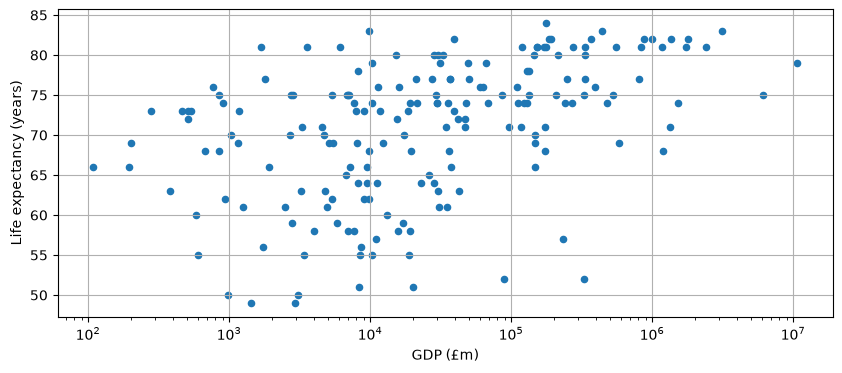

In [43]:
gdpVsLifePopulationClean.plot(
    x=GDP,
    y=LIFE,
    kind="scatter",
    grid=True,
    logx=True,
    figsize=(10,4)
)

<Axes: xlabel='GDP (£m)', ylabel='Population (millions)'>

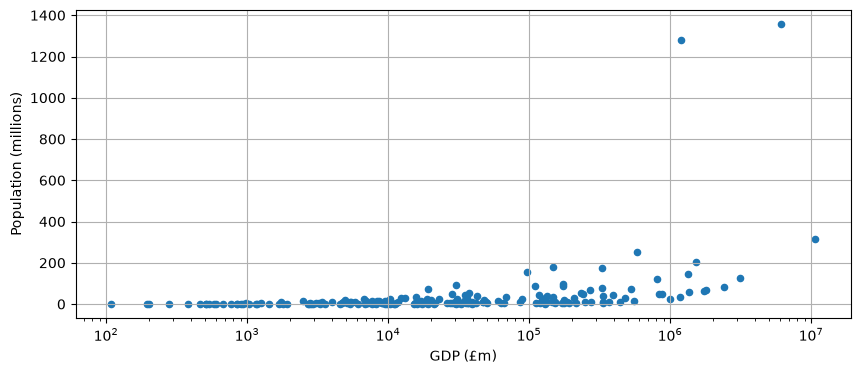

In [44]:
gdpVsLifePopulationClean.plot(
    x=GDP,
    y=POPULATION,
    kind="scatter",
    grid=True,
    logx=True,
    figsize=(10,4)
)

In [45]:
lowest_gdp = gdpVsLife.sort_values(
    GDP, ascending=True
).head(10)

display(lowest_gdp[[COUNTRY, GDP, LIFE]])

,country,GDP (£m),Life expectancy (years)
87,Kiribati,108,66.0
141,Sao Tome and Principe,195,66.0
111,"Micronesia, Fed. Sts.",202,69.0
168,Tonga,277,73.0
37,Comoros,383,63.0
157,St. Vincent and the Grenadines,461,73.0
140,Samoa,509,73.0
180,Vanuatu,512,72.0
65,Grenada,538,73.0
60,"Gambia, The",578,60.0


In [46]:
gdp_original = gdpCountries[
    [COUNTRY, GDP_INDICATOR]
].copy()

pop_original = popCountries[
    [COUNTRY, POP_INDICATOR]
].copy()

per_capita = pd.merge(
    gdp_original,
    pop_original,
    on=COUNTRY,
    how="inner"
)

per_capita["GDP per capita (US$)"] = (
    per_capita[GDP_INDICATOR] / per_capita[POP_INDICATOR]
)

display(
    per_capita[
        [COUNTRY, "GDP per capita (US$)"]
    ].sort_values("GDP per capita (US$)", ascending=False).head(10)
)

,country,GDP per capita (US$)
101,Luxembourg,113726.638979
128,Norway,102832.258690
140,Qatar,96076.996376
102,"Macao SAR, China",90331.819132
19,Bermuda,85748.065414
167,Switzerland,84669.292937
8,Australia,67627.773335
166,Sweden,60283.245223
47,Denmark,59818.631528
151,Singapore,55979.757049


In [47]:
top10_gdp = gdpVsLife.sort_values(
    GDP, ascending=False
).head(10)

top10_life = gdpVsLife.sort_values(
    LIFE, ascending=False
).head(10)

print("Ten highest-GDP countries:")
display(top10_gdp[[COUNTRY, GDP, LIFE]])

print("Ten highest-life-expectancy countries:")
display(top10_life[[COUNTRY, LIFE, GDP]])

common_countries = sorted(
    set(top10_gdp[COUNTRY]) & set(top10_life[COUNTRY])
)

print("Countries appearing in both lists:", common_countries)
print("Number appearing in both lists:", len(common_countries))

Ten highest-GDP countries:


,country,GDP (£m),Life expectancy (years)
177,United States,10715999,79.0
35,China,6065182,75.0
83,Japan,3143957,83.0
62,Germany,2393529,81.0
58,France,1795953,82.0
176,United Kingdom,1733354,81.0
23,Brazil,1528714,74.0
81,Italy,1363486,82.0
138,Russian Federation,1328647,71.0
75,India,1189826,68.0


Ten highest-life-expectancy countries:


,country,Life expectancy (years),GDP (£m)
72,"Hong Kong SAR, China",84.0,176220
74,Iceland,83.0,9827
162,Switzerland,83.0,437713
83,Japan,83.0,3143957
80,Israel,82.0,186870
81,Italy,82.0,1363486
58,France,82.0,1795953
99,Luxembourg,82.0,39491
7,Australia,82.0,999478
161,Sweden,82.0,369858


Countries appearing in both lists: ['France', 'Italy', 'Japan']
Number appearing in both lists: 3


In [48]:
median_gdp = gdpVsLife[GDP].median()

low_life_high_gdp = gdpVsLife[
    (gdpVsLife[GDP] > median_gdp) &
    (gdpVsLife[LIFE] < 60)
].sort_values(GDP, ascending=False)

print("Median GDP (£m):", median_gdp)

display(
    low_life_high_gdp[[COUNTRY, GDP, LIFE]]
)

Median GDP (£m): 21246.5


,country,GDP (£m),Life expectancy (years)
124,Nigeria,329100,52.0
152,South Africa,234056,57.0
3,Angola,88420,52.0


PROJECT B

LOADING WORD BANK DATA

In [49]:
import requests
import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

indicators = {
    "agriculture_employment_pct": "SL.AGR.EMPL.ZS",
    "cereal_yield_kg_ha": "AG.YLD.CREL.KG"
}

def download_world_bank_indicator(indicator_code, year=2013):
    url = (
        f"https://api.worldbank.org/v2/country/all/indicator/"
        f"{indicator_code}"
    )

    response = requests.get(
        url,
        params={
            "date": year,
            "format": "json",
            "per_page": 20000
        },
        timeout=60
    )

    response.raise_for_status()
    payload = response.json()

    if len(payload) < 2 or payload[1] is None:
        raise ValueError(
            f"No data returned for {indicator_code} in {year}"
        )

    records = []

    for item in payload[1]:
        country = item.get("country", {}).get("value")
        value = item.get("value")

        
        country_world = item.get("country", {})
        region_id = country_world.get("id")

        if country and value is not None:
            records.append({
                "country": country,
                "value": value
            })

    return pd.DataFrame(records)

In [50]:
def download_country_indicator(indicator_code, year=2013):
    url = (
        f"https://api.worldbank.org/v2/country/all/indicator/"
        f"{indicator_code}"
    )

    response = requests.get(
        url,
        params={
            "date": year,
            "format": "json",
            "per_page": 20000
        },
        timeout=60
    )

    response.raise_for_status()
    payload = response.json()

    records = []

    for item in (payload[1] if len(payload) > 1 and payload[1] else []):
        country_world = item.get("country", {})
        region = country_world.get("region", {})
        value = item.get("value")

        if (
            value is not None
            and region.get("id") != "NA"
            and country_world.get("id")
        ):
            records.append({
                "country": country_world.get("value"),
                "value": value
            })

    return pd.DataFrame(records)

The code
SL.AGR.EMPL.ZS
% /Agriculture employment 
AG.YLD.CREL.KG
kg per hectare /Cereal yield


In [51]:
agri_employment = download_country_indicator(
    "SL.AGR.EMPL.ZS", 2013
).rename(columns={"value": "agriculture_employment_pct"})

cereal_yield = download_country_indicator(
    "AG.YLD.CREL.KG", 2013
).rename(columns={"value": "cereal_yield_kg_ha"})

agri_project = pd.merge(
    agri_employment,
    cereal_yield,
    on="country",
    how="inner"
).dropna()

display(agri_project.head())
print("Countries with both indicators:", len(agri_project))

,country,agriculture_employment_pct,cereal_yield_kg_ha
0,Africa Eastern and Southern,59.668604,1531.994682
1,Africa Western and Central,47.243360,1130.681807
2,Arab World,20.084517,1976.493652
3,Caribbean small states,8.208021,4642.303295
4,Central Europe and the Baltics,10.583940,4149.561362


Countries with both indicators: 223


In [52]:
corr, p_value = spearmanr(
    agri_project["agriculture_employment_pct"],
    agri_project["cereal_yield_kg_ha"]
)

print("Spearman correlation:", corr)
print("P-value:", p_value)

if p_value < 0.05:
    print("The relationship is statistically significant.")
else:
    print("The relationship is not statistically significant.")

Spearman correlation: -0.5836974450275194
P-value: 9.28659899892084e-22
The relationship is statistically significant.


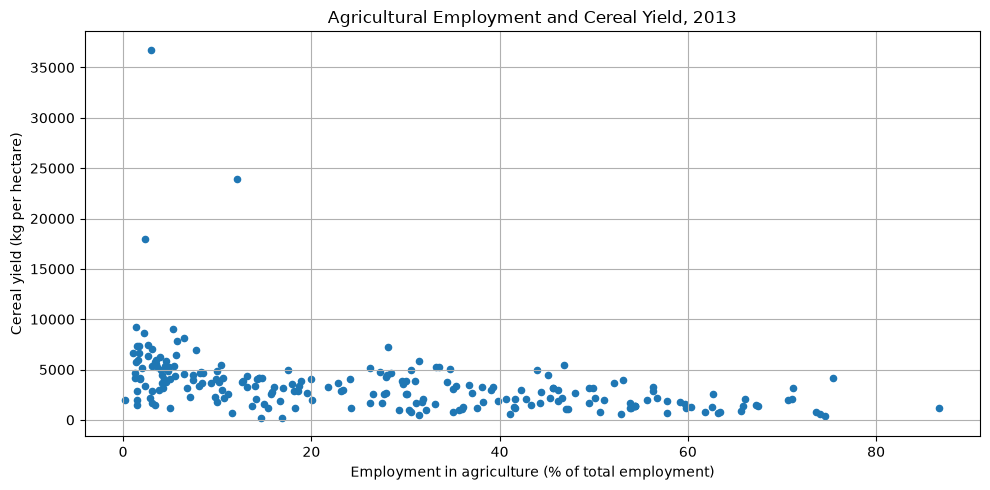

In [53]:
agri_project.plot(
    x="agriculture_employment_pct",
    y="cereal_yield_kg_ha",
    kind="scatter",
    grid=True,
    figsize=(10, 5)
)

plt.title("Agricultural Employment and Cereal Yield, 2013")
plt.xlabel("Employment in agriculture (% of total employment)")
plt.ylabel("Cereal yield (kg per hectare)")
plt.tight_layout()
plt.show()

This project examined the relationship between the share of employment in agriculture and cereal yield across countries in 2013. The analysis combined two World Bank indicators using country names and retained countries with available values for both variables. Spearman's rank correlation was used to assess the direction and strength of the relationship, and a scatterplot was used to inspect the overall pattern. The correlation coefficient and p-value indicate whether the observed association is positive or negative and whether it is statistically significant. The findings describe an association rather than a causal relationship. Differences in irrigation, mechanisation, farm inputs, climate, land quality and agricultural policy may also influence cereal yields.
 Finally , there is a moderate negative correlation (r=-0.58, p<0.001>) between agriculture employment and cereal yield.As the share of employment in agriculture increases, cereal yield decreases.

SQL PRACTICE

In [54]:
from db.practice import Practice, q

In [55]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   1,
   1
  ],
  "1ba5edf59854386be920ac9fd3e4a2af3bb6369bf2a1aef78dcdf908c96d70a9"
 ],
 "s02": [
  [
   5,
   3
  ],
  "19042d389224a7f56403ad9636ed581989f6639acadf45b15461f55cd6258da7"
 ],
 "s03": [
  [
   10,
   3
  ],
  "e3e296058facb3595b46ac98fb75d445a82240fc775f3188d029eabc5a362ddb"
 ],
 "s04": [
  [
   1,
   1
  ],
  "ba4a24ee999caa9e01607eb78856b7212bcce521b0f6fd42d8aa90541c10382d"
 ],
 "s05": [
  [
   1,
   2
  ],
  "8153d8bbbc1b43b88ce7e4ea0c99a4ac07f4b19e0f62a9a1e04df3271f2ad3df"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Cleaning a messy column",
 "s02": "Dates: a date range",
 "s03": "Combining tables (JOIN)",
 "s04": "What gets lost in a join?",
 "s05": "Window: the driest summer week"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly


In [56]:
SQL_01 = """
SELECT COUNT(*) AS days_over_350
FROM week07.london_2014
WHERE TRY_CAST(REPLACE([WindDirDegrees<br />], '<br />', '') AS INT) > 350
"""

p.sql("s01", SQL_01)

,days_over_350
0,5


✅ s01: correct!


,days_over_350
0,5


2

In [57]:
SQL_02 = """
  SELECT
       TRY_CONVERT(date, GMT) AS day,
       [Max TemperatureC],
       [Min TemperatureC]
  FROM week07.london_2014
  WHERE TRY_CONVERT(date, GMT) BETWEEN '2014-12-08' AND '2014-12-12'
  ORDER BY TRY_CONVERT(date, GMT)
"""
p.sql("s02", SQL_02)

,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


✅ s02: correct!


,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


3

In [58]:
SQL_03 = """
  SELECT TOP 10
    g.country,
    ROUND(g.[NY.GDP.MKTP.CD] / 1000000000.0, 2)
        AS gdp_bn_usd,
    ROUND(l.[SP.DYN.LE00.IN], 1)
        AS life_expectancy
FROM week08.wb_gdp_2013 AS g
INNER JOIN week08.wb_le_2013 AS l
    ON g.country = l.country
WHERE g.[NY.GDP.MKTP.CD] < 10000000000
  AND l.[SP.DYN.LE00.IN] IS NOT NULL
ORDER BY
    l.[SP.DYN.LE00.IN] DESC,
    g.country ASC;
"""
p.sql("s03", SQL_03)

,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


✅ s03: correct!


,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


4

In [59]:
SQL_04 = """
SELECT COUNT(*) AS rows_lost
FROM week08.wb_gdp_2013 AS g
LEFT JOIN week08.wb_le_2013 AS l
    ON g.country = l.country
WHERE g.[NY.GDP.MKTP.CD] IS NULL
   OR l.[SP.DYN.LE00.IN] IS NULL;

"""
p.sql("s04", SQL_04)

,rows_lost
0,29


✅ s04: correct!


,rows_lost
0,29


5

In [60]:
SQL_05 = """
  WITH summer_weather AS (
    SELECT
        TRY_CONVERT(date, GMT) AS day,
        TRY_CAST([Precipitationmm] AS float) AS rain_mm
    FROM week07.london_2014
    WHERE TRY_CONVERT(date, GMT)
        BETWEEN '2014-06-01' AND '2014-08-31'
),
rolling_rain AS (
    SELECT
        day,
        SUM(rain_mm) OVER (
            ORDER BY day
            ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING
        ) AS rain_mm_7d,
        COUNT(*) OVER (
            ORDER BY day
            ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING
        ) AS days_in_window
    FROM summer_weather
)
SELECT TOP 1
    day AS start_day,
    ROUND(rain_mm_7d, 2) AS rain_mm_7d
FROM rolling_rain
WHERE days_in_window = 7
ORDER BY rain_mm_7d ASC, day ASC;
"""
p.sql("s05", SQL_05)

,start_day,rain_mm_7d
0,2014-06-19,0.0


✅ s05: correct!


,start_day,rain_mm_7d
0,2014-06-19,0.0


In [61]:
p.score()

Task Type                          Topic Result
 s01  SQL        Cleaning a messy column      ✅
 s02  SQL            Dates: a date range      ✅
 s03  SQL        Combining tables (JOIN)      ✅
 s04  SQL      What gets lost in a join?      ✅
 s05  SQL Window: the driest summer week      ✅
SQL score: 5 / 5


,Task,Type,Topic,Result
0,s01,SQL,Cleaning a messy column,✅
1,s02,SQL,Dates: a date range,✅
2,s03,SQL,Combining tables (JOIN),✅
3,s04,SQL,What gets lost in a join?,✅
4,s05,SQL,Window: the driest summer week,✅
